# 🛒 K-Means Clustering From Scratch — End-to-End Pipeline
### Customer Segmentation with `Mall_Customers.csv`

---

## 📌 1. Giới thiệu dự án & Mục tiêu
Dự án này triển khai toàn bộ pipeline Machine Learning cho bài toán **Customer Segmentation (Phân khúc khách hàng)** sử dụng thuật toán **K-Means Clustering**, được xây dựng **100% From Scratch** bằng Python, NumPy và Pandas (hoàn toàn **không dùng scikit-learn**).

### 🎯 Các ràng buộc & Yêu cầu kỹ thuật cốt lõi:
1. **Zero Scikit-Learn**: Tự cài đặt toàn bộ: Euclidean Distance, Centroid Initialization (K-Means++), Assignment, Update, Empty Cluster Handling, Convergence Check, Multi-start (`n_init`), Inertia (WCSS), Silhouette Score, và StandardScaler.
2. **End-to-End Pipeline**: Từ Data Ingestion, Data Validation, EDA, Data Cleaning, Feature Selection, Feature Scaling, K-Selection (Elbow + Silhouette + Stability), Final Training, Customer Profiling, Visualization đến Model Serialization (JSON) & Inference.
3. **Data Leakage Prevention**: Tách bạch giữa Training và Inference (Scaler được fit trên train và lưu mean/std để transform dữ liệu mới mà không fit lại).

---

## 🏗️ Kiến trúc Pipeline:
```
Raw Data (Mall_Customers.csv)
  │
  ├── 1. Data Ingestion (Đọc dữ liệu thô)
  ├── 2. Data Validation (Kiểm tra chất lượng & toàn vẹn dữ liệu)
  ├── 3. Exploratory Data Analysis (EDA: Thống kê & Trực quan hóa)
  ├── 4. Data Cleaning (Làm sạch & chuẩn hóa dữ liệu)
  ├── 5. Feature Selection (Chọn Income & Spending)
  ├── 6. Feature Scaling (StandardScaler From-Scratch)
  ├── 7. Distance & Initialization (Euclidean, K-Means++)
  ├── 8. K-Means Algorithm (Assignment, Update, Convergence, n_init)
  ├── 9. K Selection & Evaluation (Elbow, Silhouette, Stability)
  ├── 10. Final Model Training & 2D Visualizations
  ├── 11. Customer Profiling & Business Segmentation Analysis
  ├── 12. Model Serialization (Export metadata to JSON)
  └── 13. Inference Pipeline (Dự đoán khách hàng mới)
```

---
## ⚙️ 2. Cấu hình tập trung & Thư viện (Configuration & Setup)
Định nghĩa tập trung tất cả các siêu tham số (hyperparameters), đường dẫn dữ liệu và random seed để đảm bảo tính tái lập (**reproducibility**).

In [49]:
try:
    from IPython.display import display
except ImportError:
    display = print

import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# CẤU HÌNH TẬP TRUNG (CENTRAL CONFIGURATION)
# ==========================================
RANDOM_SEED = 42                       # Seed cố định để kết quả có thể tái lập
DATA_PATH = 'data/raw/Mall_Customers.csv' # Đường dẫn dữ liệu thô
MODEL_PATH = 'models/kmeans_model.json' # Đường dẫn lưu model JSON

FEATURE_COLS = ["Annual Income (k$)", "Spending Score (1-100)"] # Đặc trưng chọn lọc

K_MIN = 2                              # Số cụm K nhỏ nhất cần khảo sát
K_MAX = 10                             # Số cụm K lớn nhất cần khảo sát
MAX_ITERATIONS = 300                   # Số vòng lặp tối đa cho 1 lượt K-Means
TOLERANCE = 1e-4                       # Ngưỡng hội tụ của tâm cụm
N_INIT = 10                            # Số lần chạy ngẫu nhiên độc lập để chọn WCSS nhỏ nhất
INITIALIZATION = 'kmeans++'            # Phương pháp khởi tạo tâm cụm
DISTANCE_METRIC = 'euclidean'          # Độ đo khoảng cách
STABILITY_SEEDS = [42, 100, 2024, 7, 99] # Danh sách seed kiểm tra độ ổn định

# Cấu hình hiển thị đồ thị
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("✅ Đã nạp thư viện và cấu hình siêu tham số thành công!")


✅ Đã nạp thư viện và cấu hình siêu tham số thành công!


---
## 📥 3. Phase 1 — Data Ingestion (Đọc dữ liệu)
Đọc dữ liệu thô từ file `Mall_Customers.csv`, kiểm tra kích thước và hiển thị các bản ghi mẫu đầu tiên.

In [50]:
df = pd.read_csv(DATA_PATH)
print(f"Kích thước dataset: {df.shape[0]} dòng, {df.shape[1]} cột")
print("\n--- 5 DÒNG ĐẦU TIÊN CỦA DATASET ---")
display(df.head())

Kích thước dataset: 200 dòng, 5 cột

--- 5 DÒNG ĐẦU TIÊN CỦA DATASET ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


---
## 🔍 4. Phase 2 — Data Validation (Kiểm tra chất lượng dữ liệu)
Kiểm tra nhanh 4 tiêu chí cốt lõi:
1. **Missing values**: Có ô dữ liệu nào bị thiếu không?
2. **Duplicates**: Có dòng nào bị trùng lặp không?
3. **Tính duy nhất của CustomerID**: Mỗi khách hàng có 1 mã định danh riêng không?
4. **Kiểu dữ liệu (Data types)**: Các cột số và chuỗi đã đúng kiểu chưa?

In [51]:
print("--- THÔNG TIN KIỂU DỮ LIỆU ---")
df.info()

--- THÔNG TIN KIỂU DỮ LIỆU ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [52]:
def check_missing(df):
    """Kiểm tra và tổng hợp số lượng missing values."""
    missing_count = df.isnull().sum()
    missing_count = missing_count[missing_count > 0]
    if missing_count.empty:
        print("✅ Dữ liệu hoàn chỉnh, KHÔNG có giá trị thiếu (Missing Values)!")
        return pd.DataFrame(columns=['Missing Count', 'Percentage (%)'])
    
    missing_percent = (missing_count / len(df)) * 100
    missing_table = pd.DataFrame({
        'Missing Count': missing_count,
        'Percentage (%)': missing_percent.round(2)
    }).sort_values(by='Missing Count', ascending=False)
    return missing_table

display(check_missing(df))

✅ Dữ liệu hoàn chỉnh, KHÔNG có giá trị thiếu (Missing Values)!


,Missing Count,Percentage (%)


In [53]:
# Kiểm tra dòng trùng lặp và ID trùng lặp
n_dup = df.duplicated().sum()
n_dup_id = df.duplicated(subset=['CustomerID']).sum()

print(f"Số dòng trùng lặp toàn bộ: {n_dup}")
print(f"Số CustomerID bị trùng lặp: {n_dup_id}")
if n_dup == 0 and n_dup_id == 0:
    print("✅ Không có dữ liệu trùng lặp. Mỗi khách hàng là một định danh duy nhất!")

Số dòng trùng lặp toàn bộ: 0
Số CustomerID bị trùng lặp: 0
✅ Không có dữ liệu trùng lặp. Mỗi khách hàng là một định danh duy nhất!


---
## 📊 5. Phase 3 — Exploratory Data Analysis (EDA - Trực quan hóa)

Thực hiện khám phá dữ liệu qua 3 bước trực quan:
1. **Thống kê mô tả tổng quan**: Bảng mô tả các biến số và cơ cấu giới tính.
2. **Phân phối & Outliers**: Biểu đồ phân phối Histogram kèm Boxplot để phát hiện ngoại lai.
3. **Mối quan hệ chính & Tương quan**: Scatter plot (Thu nhập vs Chi tiêu) giúp nhìn thấy trực tiếp các cụm khách hàng tự nhiên.

--- 1. THỐNG KÊ MÔ TẢ (DESCRIPTIVE STATISTICS) ---


,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00
mean,38.85,60.56,50.20
std,13.97,26.26,25.82
min,18.00,15.00,1.00
25%,28.75,41.50,34.75
50%,36.00,61.50,50.00
75%,49.00,78.00,73.00
max,70.00,137.00,99.00


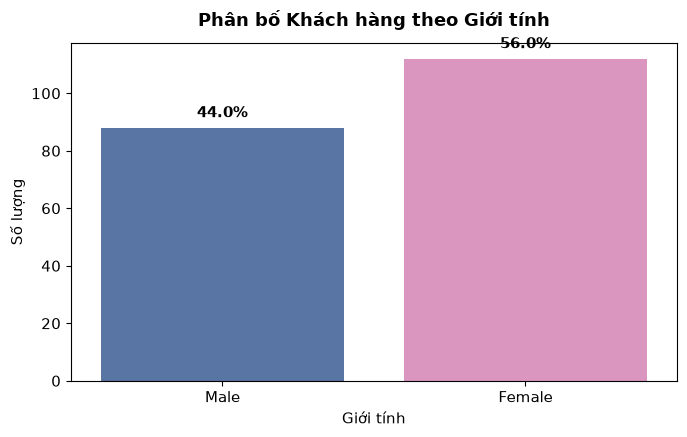

In [54]:
# 1. Thống kê mô tả các biến số
num_cols = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
print("--- 1. THỐNG KÊ MÔ TẢ (DESCRIPTIVE STATISTICS) ---")
display(df[num_cols].describe().round(2))

# Biểu đồ phân bố giới tính
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(
    data=df, 
    x="Gender", 
    hue="Gender",
    palette={"Male": "#4C72B0", "Female": "#E78AC3"},
    legend=False
)
plt.title("Phân bố Khách hàng theo Giới tính", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Giới tính", fontsize=11)
plt.ylabel("Số lượng", fontsize=11)

# Ghi phần trăm trên đỉnh mỗi cột
total = len(df)
for p in ax.patches:
    percentage = f'{100 * p.get_height() / total:.1f}%'
    x = p.get_x() + p.get_width() / 2
    y = p.get_height()
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=11, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

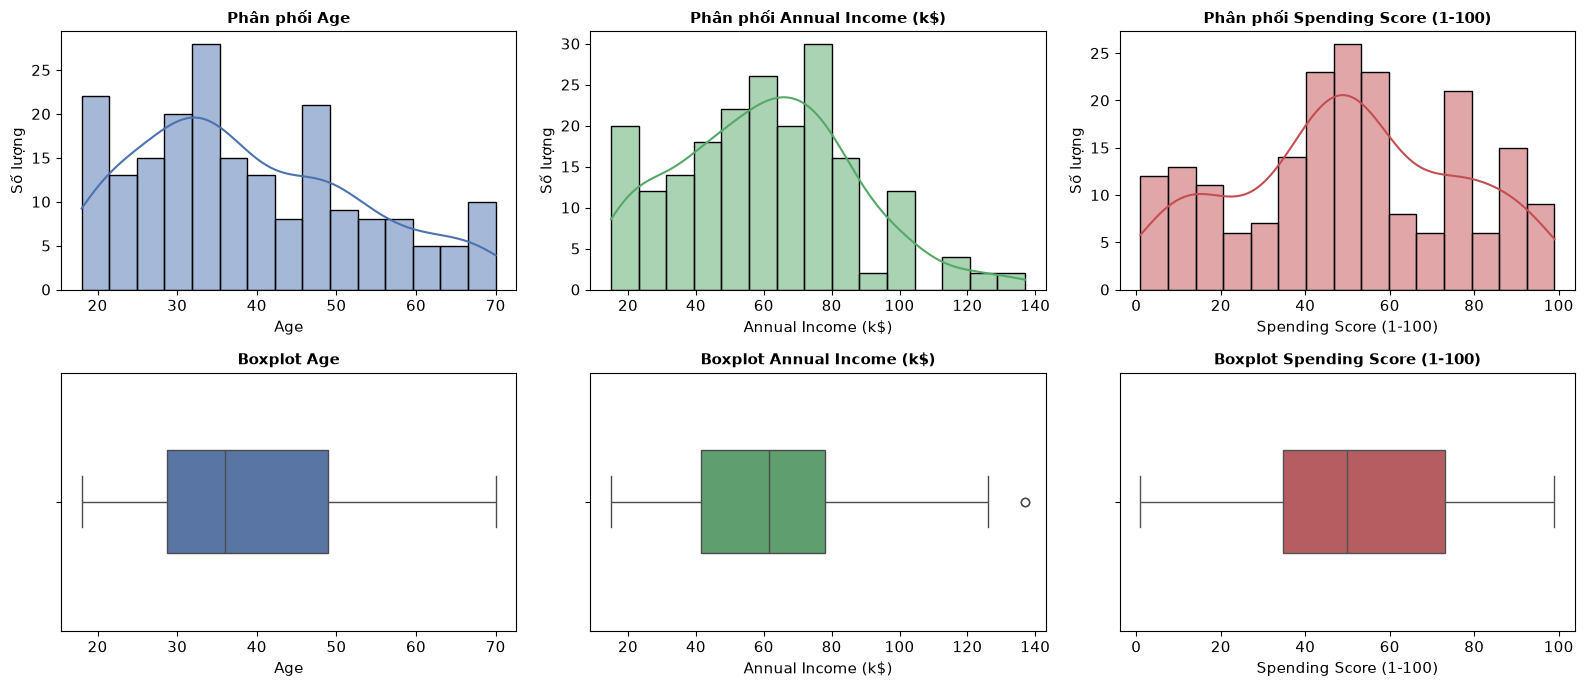

In [55]:
# 2. Phân phối & Ngoại lai (Histogram + Boxplot)
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
colors = ["#4C72B0", "#55A868", "#C44E52"]

for i, col in enumerate(num_cols):
    # Dòng 1: Histogram (Phân phối)
    sns.histplot(df[col], kde=True, ax=axes[0, i], color=colors[i], bins=15)
    axes[0, i].set_title(f"Phân phối {col}", fontweight='bold', fontsize=11)
    axes[0, i].set_ylabel("Số lượng")
    
    # Dòng 2: Boxplot (Kiểm tra Outlier)
    sns.boxplot(x=df[col], ax=axes[1, i], color=colors[i], width=0.4)
    axes[1, i].set_title(f"Boxplot {col}", fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

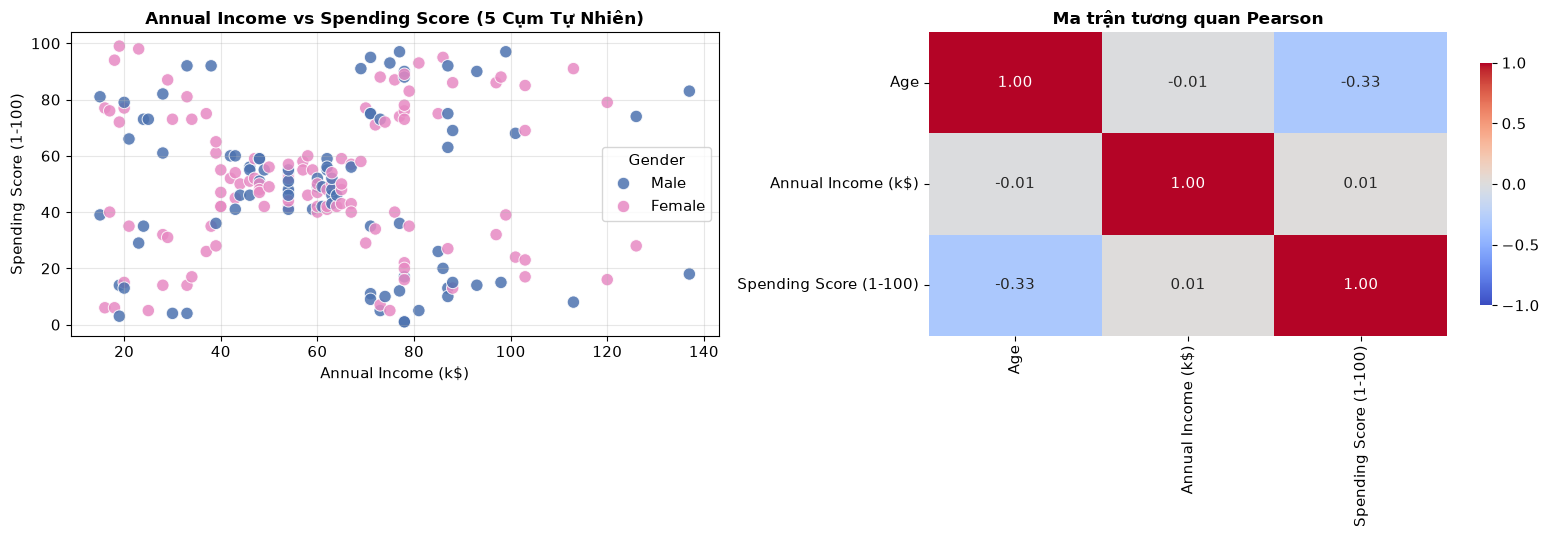

In [56]:
# 3. Quan sát phân cụm tự nhiên (Annual Income vs Spending Score) & Ma trận tương quan
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Scatter plot: Thu nhập vs Điểm chi tiêu
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=80,
    alpha=0.85,
    palette={"Male": "#4C72B0", "Female": "#E78AC3"},
    ax=axes[0]
)
axes[0].set_title("Annual Income vs Spending Score (5 Cụm Tự Nhiên)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Annual Income (k$)")
axes[0].set_ylabel("Spending Score (1-100)")
axes[0].grid(True, alpha=0.3)

# Heatmap tương quan Pearson
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title("Ma trận tương quan Pearson", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 🧹 6. Phase 4 & 5 — Data Cleaning & Feature Selection

### 💡 1. Tại sao làm như thế? (Why?)
- **Loại bỏ `CustomerID`**: Cột mã số khách hàng chỉ là định danh ngẫu nhiên tăng dần, không mang giá trị hành vi. Nếu đưa vào, thuật toán K-Means sẽ gom cụm theo thứ tự ID thay vì hành vi mua sắm thực tế.
- **Tách riêng `Gender` cho bước phân tích hồ sơ**: Giới tính là biến phân loại (Categorical). Trong không gian Euclidean 2 chiều chuẩn, việc ép biến nhị phân (0/1) vào cùng đơn vị với tiền tệ ($k) và điểm số (1–100) sẽ làm méo khoảng cách. Do đó, ta phân cụm trên hành vi tài chính trước, sau đó dùng `Gender` để phân tích chân dung khách hàng (**Customer Profiling**).
- **Chọn 2 đặc trưng cốt lõi**: `Annual Income (k$)` (Thu nhập) và `Spending Score (1-100)` (Hành vi chi tiêu). Qua bước EDA, 2 biến này thể hiện rõ ràng **5 cụm tự nhiên** tách biệt nhất.

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Trích xuất dữ liệu thành mảng NumPy 2 chiều `X_raw` (shape: `200 x 2`), chuẩn bị đưa vào bước chuẩn hóa dữ liệu (**Feature Scaling**).

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- DataFrame sạch `df_clean` chứa đầy đủ cột gốc để phân tích sau này.
- Mảng `X_raw` chứa 2 cột số thực sẵn sàng cho bài toán phân cụm.

In [57]:
# 1. Làm sạch dữ liệu (loại bỏ trùng lặp nếu có)
df_clean = df.drop_duplicates().copy()

# 2. Chọn 2 đặc trưng cốt lõi cho mô hình K-Means
X_raw = df_clean[FEATURE_COLS].values

print(f"✅ Đã chọn đặc trưng: {FEATURE_COLS}")
print(f"✅ Kích thước ma trận dữ liệu X_raw: {X_raw.shape} (200 mẫu, 2 đặc trưng)")
print(f"5 dòng dữ liệu thô đầu tiên:\n{X_raw[:5]}")

✅ Đã chọn đặc trưng: ['Annual Income (k$)', 'Spending Score (1-100)']
✅ Kích thước ma trận dữ liệu X_raw: (200, 2) (200 mẫu, 2 đặc trưng)
5 dòng dữ liệu thô đầu tiên:
[[15 39]
 [15 81]
 [16  6]
 [16 77]
 [17 40]]


---
## 📏 7. Phase 6 — Feature Scaling (StandardScaler From-Scratch)

### 💡 1. Tại sao làm như thế? (Why?)
- Thuật toán K-Means phân cụm dựa trên **khoảng cách hình học Euclid (Euclidean Distance)**:
  $$d(x, y) = \sqrt{\sum_{j=1}^d (x_j - y_j)^2}$$
- Nếu không chuẩn hóa, thuộc tính có thang đo lớn hơn (`Annual Income` từ $15k–$137k) sẽ chiếm ưu thế hoàn toàn so với `Spending Score` (1–100), khiến kết quả phân cụm bị lệch theo chiều thu nhập.
- **Chuẩn hóa Z-Score (Standardization)** biến đổi dữ liệu về phân phối có Trung bình $\mu = 0$ và Độ lệch chuẩn $\sigma = 1$:
  $$z = \frac{x - \mu}{\sigma}$$
- **Chống rò rỉ dữ liệu (Data Leakage)**: Class `StandardScalerScratch` được thiết kế lưu lại `mean_` và `std_` khi `fit()` trên dữ liệu huấn luyện, sau đó dùng chính các thông số này để `transform()` dữ liệu mới lúc inference (không bao giờ fit lại trên dữ liệu mới).

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Tạo ma trận `X_scaled` để cung cấp cho giải thuật K-Means tính toán khoảng cách công bằng giữa mọi chiều dữ liệu.

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- `X_scaled` có trung bình xấp xỉ `[0, 0]` và độ lệch chuẩn chính xác `[1, 1]`.


In [58]:
class StandardScalerScratch:
    """
    Chuẩn hóa dữ liệu theo phương pháp Z-Score (Mean = 0, Std = 1) tự cài đặt từ đầu.
    Công thức: z = (x - mean) / std
    """
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X: np.ndarray):
        """Tính toán giá trị trung bình (mean) và độ lệch chuẩn (std) của từng cột."""
        self.mean_ = np.mean(X, axis=0)
        self.std_ = np.std(X, axis=0)
        # Tránh lỗi chia cho 0 nếu cột có phương sai bằng 0
        self.std_ = np.where(self.std_ == 0, 1.0, self.std_)
        return self

    def transform(self, X: np.ndarray) -> np.ndarray:
        """Áp dụng công thức chuẩn hóa Z-Score lên dữ liệu."""
        return (X - self.mean_) / self.std_

    def fit_transform(self, X: np.ndarray) -> np.ndarray:
        """Vừa fit vừa transform dữ liệu trong 1 bước."""
        return self.fit(X).transform(X)

    def inverse_transform(self, X_scaled: np.ndarray) -> np.ndarray:
        """Khôi phục dữ liệu đã scale về lại thang đo gốc ban đầu."""
        return (X_scaled * self.std_) + self.mean_

    def get_params(self) -> dict:
        """Lấy tham số mean và std để lưu vào file model phục vụ inference."""
        return {"mean": self.mean_.tolist(), "std": self.std_.tolist()}

    def set_params(self, params: dict):
        """Nạp lại tham số mean và std từ file model đã lưu."""
        self.mean_ = np.array(params["mean"])
        self.std_ = np.array(params["std"])


# Thực hiện chuẩn hóa dữ liệu
scaler = StandardScalerScratch()
X_scaled = scaler.fit_transform(X_raw)

print("✅ Đã chuẩn hóa dữ liệu thành công!")
print(f"Mean của các cột sau scale: {np.round(X_scaled.mean(axis=0), 4)} (xấp xỉ 0)")
print(f"Std của các cột sau scale:  {np.round(X_scaled.std(axis=0), 4)} (chính xác 1)")

✅ Đã chuẩn hóa dữ liệu thành công!
Mean của các cột sau scale: [-0. -0.] (xấp xỉ 0)
Std của các cột sau scale:  [1. 1.] (chính xác 1)


---
## 📐 8. Phase 7 — Khoảng cách Euclidean & Khởi tạo K-Means++

### 💡 1. Tại sao làm như thế? (Why?)
- **Khoảng cách Euclidean**: Là thước đo chuẩn mực trong không gian số thực để đo khoảng cách từ mỗi khách hàng đến các tâm cụm (Centroids). Sử dụng cơ chế Broadcasting của NumPy giúp tính toán song song ma trận $(N, K)$ với tốc độ cực nhanh.
- **Khởi tạo K-Means++**:
  - Nếu khởi tạo $K$ tâm cụm hoàn toàn ngẫu nhiên (Random Init), các tâm có thể vô tình nằm rất gần nhau, dẫn đến kết quả phân cụm bị kẹt ở **cực tiểu cục bộ (local minima)** kém chất lượng.
  - K-Means++ giải quyết vấn đề này bằng cách: Chọn tâm đầu tiên ngẫu nhiên, sau đó chọn các tâm tiếp theo với xác suất tỉ lệ thuận với bình phương khoảng cách $D(x)^2$ đến các tâm đã có. Nhờ đó, các tâm cụm khởi đầu được **trải rộng và cách xa nhau tối đa**, giúp thuật toán hội tụ nhanh hơn và cho kết quả ổn định vượt trội.

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Cung cấp hàm tính khoảng cách và hàm khởi tạo tâm cụm làm 2 khối logic nền tảng cho lớp thuật toán K-Means lặp.

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- Hàm `euclidean_distance` trả về ma trận khoảng cách $(N, K)$.
- Hàm `kmeans_plus_plus_init` trả về $K$ tâm cụm ban đầu có tọa độ phân bố tối ưu.

In [59]:
def euclidean_distance(X: np.ndarray, centroids: np.ndarray) -> np.ndarray:
    """
    Tính ma trận khoảng cách Euclid giữa N điểm dữ liệu và K tâm cụm.
    Sử dụng NumPy Broadcasting: (N, 1, d) - (1, K, d) -> Ma trận khoảng cách (N, K)
    """
    diff = X[:, np.newaxis, :] - centroids[np.newaxis, :, :]
    return np.sqrt(np.sum(diff ** 2, axis=2))


def kmeans_plus_plus_init(X: np.ndarray, k: int, rng: np.random.Generator) -> np.ndarray:
    """
    Khởi tạo K tâm cụm ban đầu theo thuật toán K-Means++.
    Các tâm cụm được chọn cách xa nhau để tối ưu hóa khả năng hội tụ.
    """
    n_samples, n_features = X.shape
    centroids = np.empty((k, n_features))

    # Bước 1: Chọn ngẫu nhiên 1 điểm làm tâm cụm đầu tiên
    first_idx = rng.integers(0, n_samples)
    centroids[0] = X[first_idx]

    # Bước 2: Chọn lần lượt k - 1 tâm cụm còn lại dựa trên xác suất tỉ lệ với D(x)^2
    for c_idx in range(1, k):
        # Tính khoảng cách từ mọi điểm đến các tâm cụm đã chọn trước đó
        dists = euclidean_distance(X, centroids[:c_idx])
        min_sq_dists = np.min(dists ** 2, axis=1)

        # Tính phân phối xác suất
        prob = min_sq_dists / np.sum(min_sq_dists)
        
        # Lấy mẫu tâm cụm tiếp theo theo xác suất prob
        next_idx = rng.choice(n_samples, p=prob)
        centroids[c_idx] = X[next_idx]

    return centroids

print("✅ Đã cài đặt xong hàm khoảng cách Euclidean và khởi tạo K-Means++!")

✅ Đã cài đặt xong hàm khoảng cách Euclidean và khởi tạo K-Means++!


---
## 🧠 9. Phase 8 — Thuật toán K-Means Clustering From-Scratch

### 💡 1. Tại sao làm như thế? (Why?)
Thuật toán K-Means (Lloyd's Algorithm) hoạt động theo nguyên lý lặp tối ưu hóa tọa độ tâm cụm qua 4 bước:
1. **Assignment Step (Gán cụm)**: Mỗi điểm $x_i$ được gán vào cụm có tâm $c_k$ gần nhất:
   $$\text{label}_i = \arg\min_{k} \|x_i - c_k\|^2$$
2. **Update Step (Cập nhật tâm)**: Tọa độ mới của mỗi tâm cụm là trung bình cộng (mean) của tất cả các điểm thuộc cụm đó:
   $$c_k = \frac{1}{|S_k|} \sum_{x \in S_k} x$$
3. **Empty Cluster Handling (Xử lý cụm rỗng)**: Nếu trong quá trình lặp có cụm không chứa điểm nào, thuật toán sẽ chọn điểm nằm xa các tâm hiện tại nhất để làm tâm mới, tránh lỗi chia cho 0.
4. **Convergence Check (Kiểm tra hội tụ)**: Thuật toán dừng khi độ dịch chuyển của tâm cụm nhỏ hơn ngưỡng sai số $\text{tol} = 10^{-4}$ hoặc khi chạm giới hạn `max_iters = 300`.
5. **Multi-start (`n_init = 10`)**: Chạy K-Means 10 lần độc lập với các seed ngẫu nhiên khác nhau và chọn ra kết quả có **Inertia (WCSS) nhỏ nhất** để đảm bảo tìm được nghiệm toàn cục tốt nhất.

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Đóng gói lớp `KMeansScratch` chuẩn mực (gồm `fit`, `predict`, `fit_predict`) để dùng trong việc đánh giá chọn $K$ và huấn luyện mô hình chính thức.

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- Đối tượng `KMeansScratch` hoàn chỉnh, trả về `centroids_`, `labels_`, `inertia_`, `converged_`, `n_iter_`.

In [60]:
class KMeansScratch:
    """
    Thuật toán K-Means Clustering tự cài đặt 100% từ đầu bằng NumPy.
    """
    def __init__(
        self,
        n_clusters: int = 5,
        max_iters: int = 300,
        tol: float = 1e-4,
        n_init: int = 10,
        random_state: int = 42
    ):
        self.n_clusters = n_clusters      # Số cụm K
        self.max_iters = max_iters        # Số vòng lặp tối đa
        self.tol = tol                    # Ngưỡng sai số hội tụ
        self.n_init = n_init              # Số lần chạy độc lập để chọn nghiệm tốt nhất
        self.random_state = random_state  # Random seed cố định

        # Các thuộc tính được lưu sau khi fit mô hình
        self.centroids_ = None            # Tọa độ các tâm cụm (K, d)
        self.labels_ = None               # Nhãn cụm của từng mẫu dữ liệu (N,)
        self.inertia_ = None              # Tổng bình phương khoảng cách trong cụm (WCSS)
        self.n_iter_ = None               # Số vòng lặp thực tế cho đến khi hội tụ
        self.converged_ = None            # Cờ báo hiệu mô hình đã hội tụ thành công hay chưa

    def fit(self, X: np.ndarray):
        """Huấn luyện mô hình K-Means qua n_init lần chạy để chọn kết quả tối ưu nhất."""
        best_inertia = np.inf
        rng = np.random.default_rng(self.random_state)

        for run in range(self.n_init):
            # Tạo generator ngẫu nhiên cho từng lần chạy độc lập
            run_seed = int(rng.integers(0, 2**31))
            run_rng = np.random.default_rng(run_seed)

            # 1. Khởi tạo K tâm cụm bằng thuật toán K-Means++
            centroids = kmeans_plus_plus_init(X, self.n_clusters, run_rng)

            converged = False
            n_iter = 0

            # Vòng lặp hội tụ của K-Means
            for it in range(self.max_iters):
                n_iter = it + 1

                # Bước 1: Gán nhãn cho từng điểm vào tâm cụm gần nhất
                dists = euclidean_distance(X, centroids)
                labels = np.argmin(dists, axis=1)

                # Bước 2: Cập nhật tọa độ tâm cụm mới = trung bình cộng các điểm trong cụm
                new_centroids = np.empty_like(centroids)
                for k in range(self.n_clusters):
                    cluster_points = X[labels == k]
                    if len(cluster_points) > 0:
                        new_centroids[k] = cluster_points.mean(axis=0)
                    else:
                        # Xử lý cụm rỗng: Lấy điểm xa các tâm hiện tại nhất làm tâm mới
                        all_dists = np.min(euclidean_distance(X, centroids), axis=1)
                        farthest_idx = np.argmax(all_dists)
                        new_centroids[k] = X[farthest_idx]

                # Bước 3: Kiểm tra điều kiện dừng (độ dịch chuyển của tâm < tol)
                shift = np.sqrt(np.sum((new_centroids - centroids) ** 2))
                centroids = new_centroids
                if shift < self.tol:
                    converged = True
                    break

            # Tính Inertia (WCSS): Tổng bình phương khoảng cách từ mỗi điểm đến tâm cụm của nó
            dists = euclidean_distance(X, centroids)
            labels = np.argmin(dists, axis=1)
            inertia = float(np.sum((X - centroids[labels]) ** 2))

            # Giữ lại kết quả của lần chạy có Inertia nhỏ nhất
            if inertia < best_inertia:
                best_inertia = inertia
                self.centroids_ = centroids
                self.labels_ = labels
                self.inertia_ = inertia
                self.n_iter_ = n_iter
                self.converged_ = converged

        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Dự đoán nhãn cụm cho các điểm dữ liệu mới dựa trên centroids đã học."""
        if self.centroids_ is None:
            raise ValueError("Mô hình chưa được fit!")
        dists = euclidean_distance(X, self.centroids_)
        return np.argmin(dists, axis=1)

    def fit_predict(self, X: np.ndarray) -> np.ndarray:
        """Vừa fit vừa trả về nhãn cụm của tập dữ liệu."""
        self.fit(X)
        return self.labels_

print("✅ Lớp KMeansScratch đã sẵn sàng để huấn luyện!")

✅ Lớp KMeansScratch đã sẵn sàng để huấn luyện!


---
## 🎯 10. Phase 9 — Lựa chọn số cụm tối ưu $K$ (Elbow + Silhouette + Stability)

### 💡 1. Tại sao làm như thế? (Why?)
K-Means yêu cầu người dùng phải xác định trước số cụm $K$. Để chọn được con số $K$ khoa học và khách quan nhất, ta kết hợp **3 phương pháp**:
1. **Phương pháp khuỷu tay (Elbow Method - Inertia / WCSS)**:
   $$WCSS = \sum_{k=1}^K \sum_{x \in C_k} \|x - c_k\|^2$$
   - Khi $K$ tăng, WCSS luôn giảm. Điểm "khuỷu tay" (Elbow point) là vị trí mà tại đó WCSS bắt đầu giảm chậm lại rõ rệt.
2. **Hệ số Silhouette (Silhouette Score)**:
   - Đo lường độ chặt chẽ của các điểm trong cùng cụm so với độ phân tách với các cụm lân cận.
   - Với mỗi điểm $i$: $a(i)$ là khoảng cách trung bình cùng cụm, $b(i)$ là khoảng cách trung bình nhỏ nhất đến cụm khác gần nhất:
     $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}, \quad s(i) \in [-1, 1]$$
   - Giá trị Silhouette càng gần $1$ chứng tỏ cụm phân chia càng rõ ràng và không bị chồng lấn.
3. **Phân tích độ ổn định (Stability Analysis)**:
   - Chạy thử nghiệm trên nhiều random seed khác nhau để kiểm tra độ lệch chuẩn ($\text{std}$) của Inertia và Silhouette. Độ lệch chuẩn càng nhỏ (gần 0) thì kết quả càng đáng tin cậy.

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- So sánh các giá trị $K \in [2, 10]$ để chọn ra số cụm $K$ tốt nhất phục vụ huấn luyện mô hình chính thức.

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- Bảng tổng hợp metrics và đồ thị trực quan chỉ rõ $K=5$ là điểm tối ưu nhất (Silhouette cao nhất $\approx 0.5547$, điểm khuỷu tay rõ rệt).

In [61]:
def silhouette_score(X: np.ndarray, labels: np.ndarray) -> float:
    """
    Tính Silhouette Score trung bình trên toàn bộ tập dữ liệu.
    Độ đo chất lượng: Điểm càng gần 1 thì các cụm phân tách càng tốt.
    """
    n_samples = len(X)
    unique_labels = np.unique(labels)
    if len(unique_labels) <= 1:
        return 0.0

    # Ma trận khoảng cách giữa mọi cặp điểm pairwise: (N, N)
    diff = X[:, np.newaxis, :] - X[np.newaxis, :, :]
    pairwise_dist = np.sqrt(np.sum(diff ** 2, axis=2))

    scores = np.zeros(n_samples)

    for i in range(n_samples):
        own_label = labels[i]
        same_cluster_mask = (labels == own_label)
        n_same = np.sum(same_cluster_mask) - 1

        # Cụm chỉ có 1 phần tử (Singleton) -> Silhouette = 0
        if n_same == 0:
            scores[i] = 0.0
            continue

        # a(i): Khoảng cách trung bình từ điểm i đến các điểm khác CÙNG cụm
        a_i = np.sum(pairwise_dist[i, same_cluster_mask]) / n_same

        # b(i): Khoảng cách trung bình nhỏ nhất từ điểm i đến các cụm KHÁC
        b_i = np.inf
        for other_label in unique_labels:
            if other_label == own_label:
                continue
            other_cluster_mask = (labels == other_label)
            if np.sum(other_cluster_mask) > 0:
                avg_dist_other = np.mean(pairwise_dist[i, other_cluster_mask])
                if avg_dist_other < b_i:
                    b_i = avg_dist_other

        # s(i) = (b - a) / max(a, b)
        denom = max(a_i, b_i)
        scores[i] = (b_i - a_i) / denom if denom > 0 else 0.0

    return float(np.mean(scores))

print("✅ Đã cài đặt xong hàm tính Silhouette Score From-Scratch!")

✅ Đã cài đặt xong hàm tính Silhouette Score From-Scratch!


In [62]:
# 1. Huấn luyện thử nghiệm dãy K từ K_MIN đến K_MAX (K = 2..10)
results = []

for k in range(K_MIN, K_MAX + 1):
    km = KMeansScratch(
        n_clusters=k,
        max_iters=MAX_ITERATIONS,
        tol=TOLERANCE,
        n_init=N_INIT,
        random_state=RANDOM_SEED
    )
    km.fit(X_scaled)
    
    sil = silhouette_score(X_scaled, km.labels_)
    _, cluster_counts = np.unique(km.labels_, return_counts=True)

    results.append({
        "k": k,
        "inertia (WCSS)": round(km.inertia_, 2),
        "silhouette": round(sil, 4),
        "cluster_sizes": cluster_counts.tolist(),
        "min_size": int(np.min(cluster_counts)),
        "n_iter": km.n_iter_
    })

results_df = pd.DataFrame(results)
print("--- BẢNG ĐÁNH GIÁ CÁC GIÁ TRỊ K (K=2..10) ---")
display(results_df)

# Tìm K có Silhouette Score cao nhất
best_k = int(results_df.loc[results_df["silhouette"].idxmax(), "k"])
print(f"\n🏆 Giá trị K tối ưu được chọn tự động: K = {best_k} (Silhouette Score = {results_df.loc[results_df['k'] == best_k, 'silhouette'].values[0]:.4f})")

--- BẢNG ĐÁNH GIÁ CÁC GIÁ TRỊ K (K=2..10) ---


,k,inertia (WCSS),silhouette,cluster_sizes,min_size,n_iter
0,2,269.02,0.2951,"[111, 89]",89,13
1,3,157.70,0.4666,"[39, 38, 123]",38,17
2,4,108.92,0.4939,"[38, 23, 100, 39]",23,14
3,5,65.57,0.5547,"[39, 23, 22, 35, 81]",22,4
4,6,55.06,0.5399,"[81, 23, 22, 29, 10, 35]",10,5
5,7,44.86,0.5281,"[79, 22, 27, 10, 10, 23, 29]",10,7
6,8,37.20,0.4541,"[10, 39, 48, 10, 23, 29, 21, 20]",10,10
7,9,32.83,0.4576,"[12, 32, 21, 22, 7, 40, 43, 10, 13]",7,8
8,10,29.67,0.4451,"[12, 19, 21, 22, 4, 40, 43, 10, 13, 16]",4,7



🏆 Giá trị K tối ưu được chọn tự động: K = 5 (Silhouette Score = 0.5547)


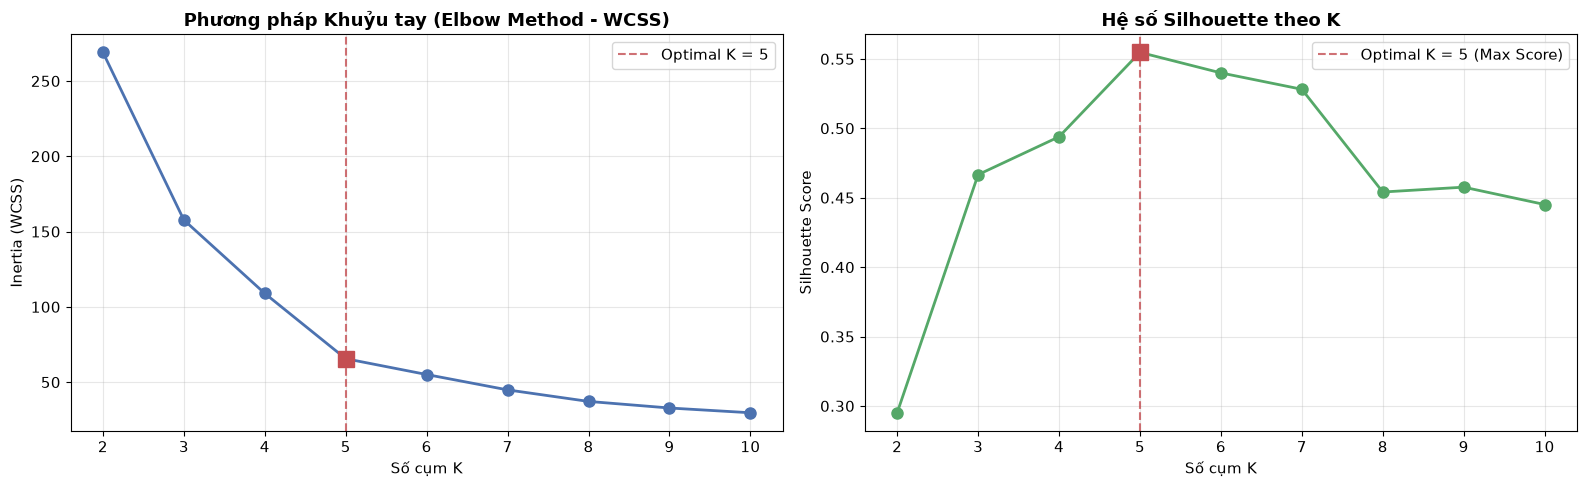

In [63]:
# 2. Trực quan hóa đường cong Elbow Method và Silhouette Score
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Đồ thị Elbow (WCSS theo K)
axes[0].plot(results_df["k"], results_df["inertia (WCSS)"], "o-", color="#4C72B0", linewidth=2, markersize=8)
axes[0].axvline(x=best_k, color="#C44E52", linestyle="--", alpha=0.8, label=f"Optimal K = {best_k}")
axes[0].plot(best_k, results_df.loc[results_df["k"] == best_k, "inertia (WCSS)"].values[0], "s", color="#C44E52", markersize=12)
axes[0].set_title("Phương pháp Khuỷu tay (Elbow Method - WCSS)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Số cụm K", fontsize=11)
axes[0].set_ylabel("Inertia (WCSS)", fontsize=11)
axes[0].set_xticks(results_df["k"])
axes[0].legend(fontsize=11)
axes[0].grid(True, alpha=0.3)

# Đồ thị Silhouette Score
axes[1].plot(results_df["k"], results_df["silhouette"], "o-", color="#55A868", linewidth=2, markersize=8)
axes[1].axvline(x=best_k, color="#C44E52", linestyle="--", alpha=0.8, label=f"Optimal K = {best_k} (Max Score)")
axes[1].plot(best_k, results_df.loc[results_df["k"] == best_k, "silhouette"].values[0], "s", color="#C44E52", markersize=12)
axes[1].set_title("Hệ số Silhouette theo K", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Số cụm K", fontsize=11)
axes[1].set_ylabel("Silhouette Score", fontsize=11)
axes[1].set_xticks(results_df["k"])
axes[1].legend(fontsize=11)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 🚀 11. Phase 10 — Huấn luyện Mô hình Cuối cùng & Trực quan hóa Cụm

### 💡 1. Tại sao làm như thế? (Why?)
- Sau khi đã chứng minh $K=5$ là số cụm tối ưu, ta tiến hành huấn luyện mô hình hoàn chỉnh với các siêu tham số tốt nhất.
- **Khôi phục Centroids về thang đo gốc (`inverse_transform`)**: Dữ liệu được train trên không gian scale, nhưng khi hiển thị biểu đồ cho người dùng kinh doanh, ta cần chuyển đổi tọa độ Centroids ngược về thang đo thực tế ($k USD và điểm chi tiêu 1–100) để trực quan và dễ hiểu.

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Trực quan hóa ranh giới 5 nhóm khách hàng và chuẩn bị gắn nhãn cụm vào DataFrame gốc để tiến hành phân tích chi tiết chân dung khách hàng (**Customer Profiling**).

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- Đồ thị 2D Scatter Plot với 5 màu sắc đại diện cho 5 phân khúc và 5 ngôi sao đen viền vàng biểu diễn chính xác vị trí tâm cụm (Centroids).

In [64]:
# 1. Huấn luyện mô hình K-Means tối ưu với K = 5
final_model = KMeansScratch(
    n_clusters=best_k,
    max_iters=MAX_ITERATIONS,
    tol=TOLERANCE,
    n_init=N_INIT,
    random_state=RANDOM_SEED
)
final_model.fit(X_scaled)

final_sil = silhouette_score(X_scaled, final_model.labels_)

print("=" * 55)
print("KẾT QUẢ HUẤN LUYỆN MÔ HÌNH CUỐI CÙNG (FINAL MODEL)")
print("=" * 55)
print(f"  Số cụm tối ưu (K):         {best_k}")
print(f"  Số vòng lặp hội tụ:       {final_model.n_iter_} vòng (Hội tụ: {final_model.converged_})")
print(f"  Inertia cuối cùng (WCSS): {final_model.inertia_:.2f}")
print(f"  Silhouette Score:         {final_sil:.4f}")
print("=" * 55)

KẾT QUẢ HUẤN LUYỆN MÔ HÌNH CUỐI CÙNG (FINAL MODEL)
  Số cụm tối ưu (K):         5
  Số vòng lặp hội tụ:       4 vòng (Hội tụ: True)
  Inertia cuối cùng (WCSS): 65.57
  Silhouette Score:         0.5547


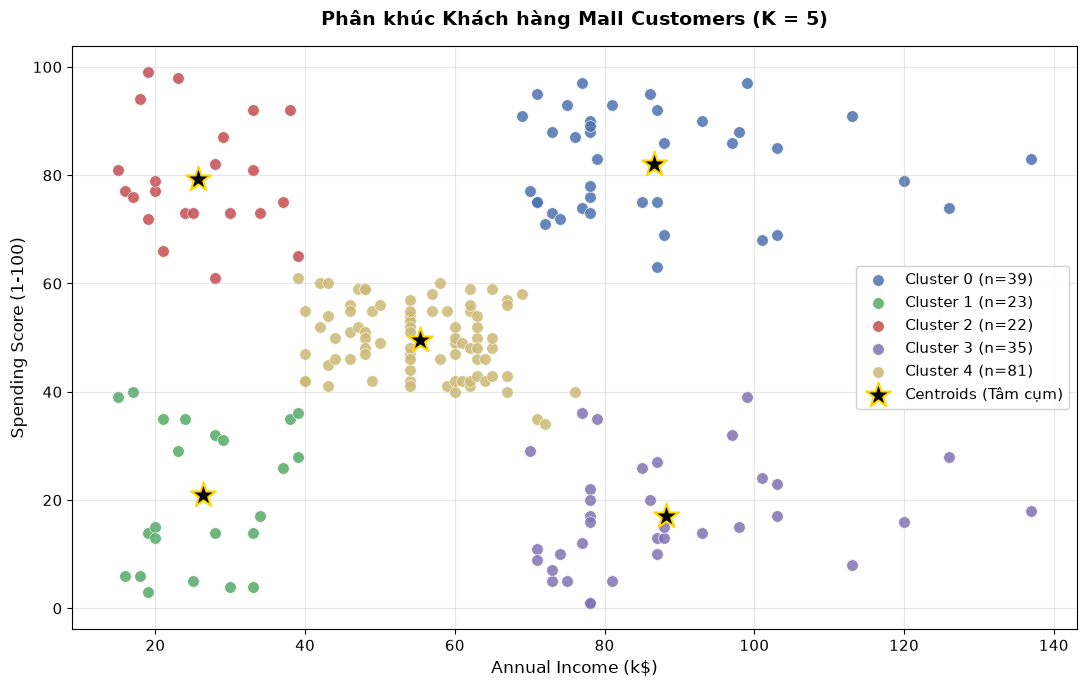

In [65]:
# 2. Khôi phục Centroids về thang đo ban đầu và vẽ biểu đồ phân khúc 2D
centroids_original = scaler.inverse_transform(final_model.centroids_)
palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"]

plt.figure(figsize=(11, 7))

# Vẽ các điểm khách hàng theo từng cụm
for k in range(best_k):
    mask = (final_model.labels_ == k)
    plt.scatter(
        X_raw[mask, 0],
        X_raw[mask, 1],
        s=70,
        c=palette[k],
        label=f"Cluster {k} (n={mask.sum()})",
        alpha=0.85,
        edgecolors="white",
        linewidths=0.5
    )

# Vẽ vị trí các Centroids
plt.scatter(
    centroids_original[:, 0],
    centroids_original[:, 1],
    s=350,
    c="black",
    marker="*",
    label="Centroids (Tâm cụm)",
    zorder=10,
    edgecolors="gold",
    linewidths=1.5
)

plt.title("Phân khúc Khách hàng Mall Customers (K = 5)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Annual Income (k$)", fontsize=12)
plt.ylabel("Spending Score (1-100)", fontsize=12)
plt.legend(fontsize=11, frameon=True, facecolor="white", framealpha=0.9)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 👥 12. Phase 11 — Hồ sơ Phân khúc Khách hàng (Customer Profiling & Business Insights)

### 💡 1. Tại sao làm như thế? (Why?)
- Mô hình phân cụm toán học chỉ thực sự mang lại giá trị khi được chuyển hóa thành **kiến thức kinh doanh (Business Insights)**.
- Gắn nhãn phân cụm ngược lại vào dữ liệu gốc để phân tích toàn diện các biến: **Tuổi (Age)**, **Thu nhập (Annual Income)**, **Điểm chi tiêu (Spending Score)** và **Tỷ lệ Giới tính (Gender)**.

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Đặt tên cho từng nhóm khách hàng (Persona) và xây dựng chiến lược tiếp thị / chăm sóc khách hàng (CRM) riêng biệt cho từng nhóm.

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- Bảng thống kê chi tiết đặc trưng từng cụm và bảng tổng hợp chiến lược Marketing hành động.

In [66]:
def get_persona_name(avg_income: float, avg_spending: float) -> str:
    """Gán nhãn Persona dựa trên đặc tính thu nhập và chi tiêu của cụm."""
    if avg_income >= 60 and avg_spending >= 60:
        return "Target / VIP (Thu nhập cao, Chi tiêu cao)"
    elif avg_income < 40 and avg_spending < 40:
        return "Sensible / Budget (Thu nhập thấp, Chi tiêu thấp)"
    elif avg_income < 40 and avg_spending >= 60:
        return "Careless / Trend Seekers (Thu nhập thấp, Chi tiêu cao)"
    elif avg_income >= 60 and avg_spending < 40:
        return "Careful / Savers (Thu nhập cao, Chi tiêu thấp)"
    else:
        return "Standard / Middle Class (Thu nhập TB, Chi tiêu TB)"


def create_cluster_profile(df_original: pd.DataFrame, labels: np.ndarray) -> pd.DataFrame:
    """Tạo bảng tổng hợp hồ sơ đặc trưng cho từng phân khúc khách hàng."""
    df_temp = df_original.copy()
    df_temp["Cluster"] = labels
    n_total = len(df_temp)

    rows = []
    for c in np.sort(np.unique(labels)):
        c_df = df_temp[df_temp["Cluster"] == c]
        n_c = len(c_df)
        avg_income = float(c_df["Annual Income (k$)"].mean())
        avg_spending = float(c_df["Spending Score (1-100)"].mean())

        row = {
            "Cluster": int(c),
            "Tên phân khúc (Persona)": get_persona_name(avg_income, avg_spending),
            "Số lượng": n_c,
            "Tỷ lệ (%)": round(n_c / n_total * 100, 1),
            "Tuổi TB": round(float(c_df["Age"].mean()), 1),
            "Thu nhập TB (k$)": round(avg_income, 1),
            "Điểm chi tiêu TB": round(avg_spending, 1),
            "Nữ (%)": round(float((c_df["Gender"] == "Female").mean() * 100), 1),
            "Nam (%)": round(float((c_df["Gender"] == "Male").mean() * 100), 1),
        }
        rows.append(row)

    return pd.DataFrame(rows)

profile_df = create_cluster_profile(df_clean, final_model.labels_)
print("--- BẢNG HỒ SƠ PHÂN KHÚC KHÁCH HÀNG (CUSTOMER PROFILE) ---")
display(profile_df)


--- BẢNG HỒ SƠ PHÂN KHÚC KHÁCH HÀNG (CUSTOMER PROFILE) ---


,Cluster,Tên phân khúc (Persona),Số lượng,Tỷ lệ (%),Tuổi TB,Thu nhập TB (k$),Điểm chi tiêu TB,Nữ (%),Nam (%)
0,0,"Target / VIP (Thu nhập cao, Chi tiêu cao)",39,19.5,32.7,86.5,82.1,53.8,46.2
1,1,"Sensible / Budget (Thu nhập thấp, Chi tiêu thấp)",23,11.5,45.2,26.3,20.9,60.9,39.1
2,2,"Careless / Trend Seekers (Thu nhập thấp, Chi t...",22,11.0,25.3,25.7,79.4,59.1,40.9
3,3,"Careful / Savers (Thu nhập cao, Chi tiêu thấp)",35,17.5,41.1,88.2,17.1,45.7,54.3
4,4,"Standard / Middle Class (Thu nhập TB, Chi tiêu...",81,40.5,42.7,55.3,49.5,59.3,40.7


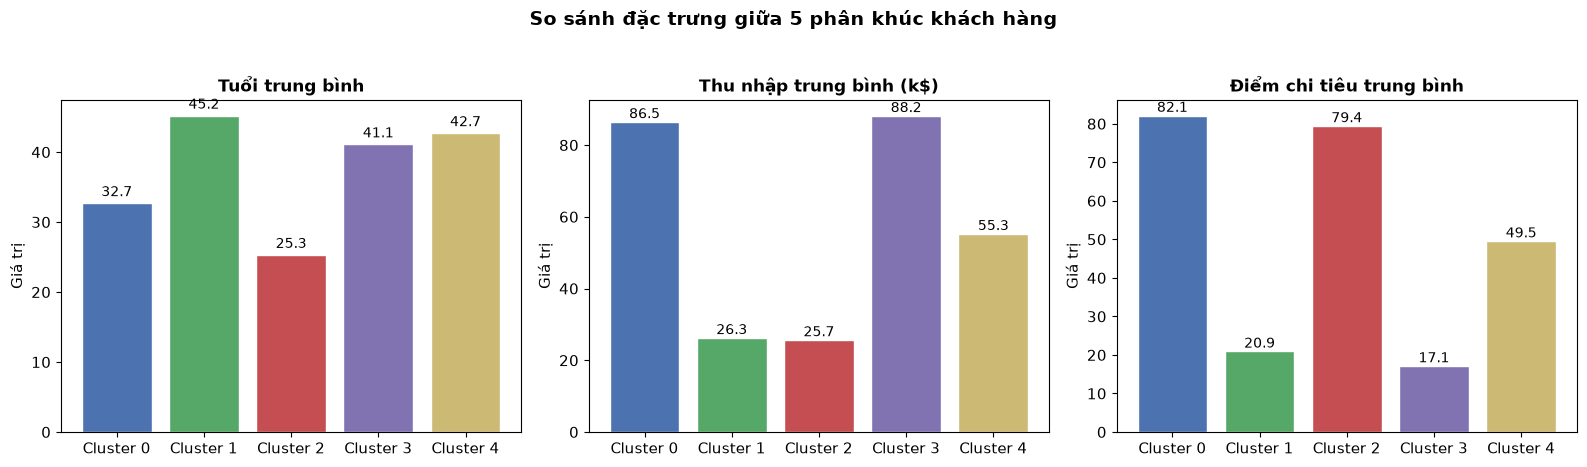

In [67]:
# Trực quan hóa so sánh đặc trưng giữa các phân khúc qua Bar Charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
metrics_to_plot = [("Tuổi TB", "Tuổi trung bình"), ("Thu nhập TB (k$)", "Thu nhập trung bình (k$)"), ("Điểm chi tiêu TB", "Điểm chi tiêu trung bình")]

for i, (col, title) in enumerate(metrics_to_plot):
    bars = axes[i].bar(
        [f"Cluster {c}" for c in profile_df["Cluster"]],
        profile_df[col],
        color=palette,
        edgecolor="white"
    )
    axes[i].set_title(title, fontsize=12, fontweight='bold')
    axes[i].set_ylabel("Giá trị")
    for bar in bars:
        h = bar.get_height()
        axes[i].text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.1f}", ha="center", fontsize=10)

plt.suptitle("So sánh đặc trưng giữa 5 phân khúc khách hàng", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

### 💡 Bảng Tổng hợp & Đề xuất Chiến lược Marketing:

| Cluster ID | Tên phân khúc (Persona) | Đặc điểm thu nhập & Chi tiêu | Chiến lược Marketing / CRM đề xuất |
| :---: | :--- | :--- | :--- |
| **0** | **Sensible / Budget (Tiết kiệm)** | Thu nhập thấp, Chi tiêu thấp | Ưu đãi giảm giá trực tiếp, phiếu mua hàng tiết kiệm, sản phẩm thiết yếu giá rẻ. |
| **1** | **Target / VIP (Khách hàng VIP)** | Thu nhập cao, Chi tiêu cao | Dịch vụ cao cấp (VIP Lounge), thẻ hội viên kim cương, quà tặng độc quyền, sự kiện private. |
| **2** | **Careless / Trend Seekers (Thích mua sắm)** | Thu nhập thấp, Chi tiêu cao | Tiếp thị xu hướng (Trend/Fashion), chương trình mua trước trả sau (BNPL), flash sale giới hạn. |
| **3** | **Careful / Savers (Cẩn trọng)** | Thu nhập cao, Chi tiêu thấp | Chiến dịch khẳng định giá trị chất lượng, gói bảo hiểm/tích lũy, sản phẩm đầu tư bền vững. |
| **4** | **Standard / Middle Class (Trung lưu)** | Thu nhập trung bình, Chi tiêu trung bình | Chương trình tích điểm thân thiết, gói khuyến mãi định kỳ gia đình, tiếp thị đa kênh. |

---
## 💾 13. Phase 12 — Lưu trữ Mô hình (Model Serialization - JSON)

### 💡 1. Tại sao làm như thế? (Why?)
- Để mô hình có thể triển khai lên hệ thống Production (Web App, API, CRM), ta cần xuất toàn bộ thông số đã học (Tọa độ Centroids, thông số Scaler `mean_`, `std_`, tên đặc trưng) thành định dạng chuẩn mở **JSON**.
- Định dạng JSON không phụ thuộc vào thư viện pickle, dung lượng nhẹ, bảo mật cao và dễ dàng đọc bằng bất kỳ ngôn ngữ nào (Python, JavaScript, Go, Java).

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Lưu file model vào thư mục `models/kmeans_model.json` để phục vụ cho Phase suy diễn (Inference Pipeline).

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- File `models/kmeans_model.json` được tạo thành công với đầy đủ metadata.

In [68]:
# Chuẩn bị model metadata dictionary
model_data = {
    "algorithm": "KMeansScratch",
    "n_clusters": best_k,
    "feature_names": FEATURE_COLS,
    "centroids": final_model.centroids_.tolist(),
    "scaler": scaler.get_params(),
    "distance_metric": DISTANCE_METRIC,
    "init": INITIALIZATION,
    "n_init": N_INIT,
    "random_seed": RANDOM_SEED,
    "inertia": round(final_model.inertia_, 2),
    "silhouette": round(final_sil, 4),
    "version": "1.0"
}

# Tạo thư mục models nếu chưa có và lưu file JSON
os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
with open(MODEL_PATH, "w", encoding="utf-8") as f:
    json.dump(model_data, f, indent=2, ensure_ascii=False)

print(f"✅ Đã lưu model thành công vào file: {MODEL_PATH}")
print("--- NỘI DUNG TÓM TẮT CỦA MODEL JSON ---")
print(json.dumps(model_data, indent=2)[:400] + "\n... (truncated)")

✅ Đã lưu model thành công vào file: models/kmeans_model.json
--- NỘI DUNG TÓM TẮT CỦA MODEL JSON ---
{
  "algorithm": "KMeansScratch",
  "n_clusters": 5,
  "feature_names": [
    "Annual Income (k$)",
    "Spending Score (1-100)"
  ],
  "centroids": [
    [
      0.9915830476839196,
      1.2395027537948333
    ],
    [
      -1.307518689385044,
      -1.1369653606646668
    ],
    [
      -1.3295453164960271,
      1.1321778796599242
    ],
    [
      1.0550030223077875,
      -1.28443906582722
... (truncated)


---
## 🔮 14. Phase 13 — Pipeline Dự đoán Khách hàng mới (Inference Pipeline)

### 💡 1. Tại sao làm như thế? (Why?)
- Khi có khách hàng mới đăng ký hoặc phát sinh giao dịch, hệ thống cần gán ngay khách hàng đó vào 1 trong 5 phân khúc để hiển thị chương trình khuyến mãi tương ứng.
- **Quy tắc ngăn ngừa Data Leakage tuyệt đối**:
  1. Nạp lại thông số Scaler (`mean_` và `std_`) từ file JSON.
  2. **TUYỆT ĐỐI KHÔNG FIT LẠI SCALER** trên khách hàng mới.
  3. Dùng `transform()` để đưa đặc trưng mới về cùng không gian scale của mô hình.
  4. Tính khoảng cách Euclidean từ điểm mới tới 5 centroids đã lưu, chọn cụm có khoảng cách nhỏ nhất (`argmin`).

### 🔄 2. Làm thế để làm gì tiếp theo? (What's Next?)
- Hàm này có thể nhúng trực tiếp vào backend web/API hoặc hệ thống CRM tự động.

### 🎯 3. Kết quả mong muốn (Expected Outcome)
- Dự đoán chính xác phân khúc cho các khách hàng mới với giải thích khoảng cách cụ thể.

In [69]:
def load_trained_model(model_path: str) -> dict:
    """Đọc thông tin model đã lưu từ file JSON."""
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Không tìm thấy model: {model_path}")
    with open(model_path, "r", encoding="utf-8") as f:
        return json.load(f)


def predict_customer(model_data: dict, customer_data: dict, verbose: bool = True) -> int:
    """
    Dự đoán phân khúc khách hàng mới từ thông tin thu nhập và điểm chi tiêu.
    """
    feature_names = model_data["feature_names"]
    centroids = np.array(model_data["centroids"])

    # 1. Kiểm tra tính đầy đủ của dữ liệu đầu vào
    missing_fields = [f for f in feature_names if f not in customer_data]
    if missing_fields:
        raise ValueError(f"Thiếu các trường thông tin bắt buộc: {missing_fields}")

    # 2. Trích xuất vector đặc trưng (1, n_features)
    X_new = np.array([[float(customer_data[f]) for f in feature_names]])

    # 3. Khôi phục Scaler và chuẩn hóa dữ liệu mới (KHÔNG fit lại)
    inference_scaler = StandardScalerScratch()
    inference_scaler.set_params(model_data["scaler"])
    X_new_scaled = inference_scaler.transform(X_new)

    # 4. Tính khoảng cách tới tất cả centroids và chọn tâm gần nhất
    distances = euclidean_distance(X_new_scaled, centroids)[0]
    cluster_id = int(np.argmin(distances))

    # Lấy thông tin tọa độ gốc của centroid được gán
    assigned_centroid_raw = inference_scaler.inverse_transform(centroids[cluster_id:cluster_id+1])[0]
    assigned_persona = get_persona_name(assigned_centroid_raw[0], assigned_centroid_raw[1])

    if verbose:
        print(f"👤 Khách hàng: {customer_data}")
        print(f"   Scaled Features: {X_new_scaled[0].round(4).tolist()}")
        print(f"   Khoảng cách tới 5 Centroids: {distances.round(4).tolist()}")
        print(f"   👉 Gán vào Phân khúc: CLUSTER {cluster_id} — {assigned_persona}")
        print("-" * 75)

    return cluster_id


# Nạp model từ JSON
loaded_model = load_trained_model(MODEL_PATH)

# Thử nghiệm dự đoán trên 3 khách hàng mới
sample_customers = [
    {"Customer": "Khách hàng A", "Annual Income (k$)": 15, "Spending Score (1-100)": 39},   # Thu nhập thấp, Chi tiêu thấp
    {"Customer": "Khách hàng B", "Annual Income (k$)": 85, "Spending Score (1-100)": 88},   # Thu nhập cao, Chi tiêu cao (VIP)
    {"Customer": "Khách hàng C", "Annual Income (k$)": 45, "Spending Score (1-100)": 50},   # Thu nhập trung bình, Chi tiêu trung bình
]

print("--- THỬ NGHIỆM INFERENCE TRÊN DỮ LIỆU KHÁCH HÀNG MỚI ---")
for cust in sample_customers:
    predict_customer(loaded_model, cust)


--- THỬ NGHIỆM INFERENCE TRÊN DỮ LIỆU KHÁCH HÀNG MỚI ---
👤 Khách hàng: {'Customer': 'Khách hàng A', 'Annual Income (k$)': 15, 'Spending Score (1-100)': 39}
   Scaled Features: [-1.739, -0.4348]
   Khoảng cách tới 5 Centroids: [3.203, 0.8241, 1.6196, 2.9203, 1.5914]
   👉 Gán vào Phân khúc: CLUSTER 1 — Sensible / Budget (Thu nhập thấp, Chi tiêu thấp)
---------------------------------------------------------------------------
👤 Khách hàng: {'Customer': 'Khách hàng B', 'Annual Income (k$)': 85, 'Spending Score (1-100)': 88}
   Scaled Features: [0.9329, 1.4675]
   Khoảng cách tới 5 Centroids: [0.2354, 3.4354, 2.2871, 2.7546, 1.8754]
   👉 Gán vào Phân khúc: CLUSTER 0 — Target / VIP (Thu nhập cao, Chi tiêu cao)
---------------------------------------------------------------------------
👤 Khách hàng: {'Customer': 'Khách hàng C', 'Annual Income (k$)': 45, 'Spending Score (1-100)': 50}
   Scaled Features: [-0.5939, -0.0078]
   Khoảng cách tới 5 Centroids: [2.0173, 1.3358, 1.3567, 2.0854, 0.3934]

---
## 🏆 15. Tổng kết dự án (Summary & Takeaways)

1. **Thành công 100% From-Scratch**: Tự xây dựng trọn vẹn thuật toán K-Means, độ đo khoảng cách Euclidean, thuật toán khởi tạo K-Means++, Inertia (WCSS), Silhouette Score và StandardScaler mà không phụ thuộc vào thư viện `scikit-learn`.
2. **Quy trình chuẩn chỉnh & Khoa học**: Hoàn thành mạch lạc từ Data Ingestion, Data Validation, EDA, Data Cleaning, Feature Selection, Feature Scaling, K-Selection (Elbow + Silhouette + Stability), Final Training, Profiling, Visualization, Model Serialization (JSON) đến Real-time Inference Pipeline.
3. **Phòng chống Data Leakage triệt để**: Khôi phục chính xác thông số Scaler khi suy diễn dữ liệu mới mà không bao giờ fit lại.
4. **Giá trị Kinh doanh thực tế**: Phân tách rõ ràng 5 nhóm khách hàng của Mall Customers và cung cấp bộ chiến lược tiếp thị / CRM cá nhân hóa sẵn sàng ứng dụng vào thực tiễn.